# Notebook 5 — Relative-Value Curve Arbitrage & Anomaly Detection

This notebook turns the Autoencoder Market Model (AEMM) of Sokol (2022) into an institutional
relative-value (RV) process: **detect** when a market curve distorts away from the VAE's historical
shape manifold, **decompose** the distortion into tradable, hedged curve packages, **trade** the
expected pull back toward the manifold, and **stop** when the distortion looks like a regime shift
rather than a temporary dislocation.

| Section | Question it answers |
|---|---|
| 1. Signal generation & monitoring | Is today's curve off the manifold, and by more than normal noise? Where is it in latent space? |
| 2. Residual decomposition & trade construction | Which tenors are mispriced, and which hedged package expresses that view? |
| 3. Mean-reversion & execution | When do we enter, how big, and when do we take profit? |
| 4. Risk controls & stop-losses | Is this a liquidity dislocation (fade it) or a regime shift (get out)? |
| 5. Backtest, benchmarks & assessment | Does it make money out of sample, after costs, versus simple benchmarks? |

**No look-ahead by construction.** The timeline has three disjoint periods:

| Period | Dates | Use |
|---|---|---|
| Fit | 2020-09-09 → 2023-12-31 | Train the CVAE (fair value) and the multi-currency VAE (latent zones) |
| Calibration | 2024 | First out-of-sample residual history for the thresholds (no trading) |
| Trading | 2025-01-01 → 2026-10-23 | Out-of-sample backtest (same window as NB4) |

All thresholds are trailing statistics of *out-of-sample* model outputs only (calibration + trading
so far). Strategy parameters are set in §0 from design principles and none was optimised on
trading-window P&L. Full disclosure: the drift detector (§1.2) and the cost-aware minimum edge were added
after an independent code review, at a point where the out-of-sample drift of the models over 2025–26
had already been seen in NB3.

## 0 — Setup and parameters

In [1]:
import pickle
import time
import warnings
from pathlib import Path
from typing import Dict, List, Optional

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR = Path("results"); RES_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (14, 6), "axes.grid": True, "grid.alpha": 0.3, "font.size": 11})

SEED = 42
TENORS = [2, 3, 5, 10, 15, 20, 30]
S_MIN, S_MAX = -0.05, 0.25          # Sokol's normalisation interval (decimal rates)
BP = 1e4
FIT_END = pd.Timestamp("2023-12-31")
TRADE_START = pd.Timestamp("2025-01-01")

# Strategy parameters — set from design principles; none optimised on trading-window P&L
# (DRIFT_* and EDGE_COST_MULT were added after a code review that had seen the 2025-26 model drift).
P = dict(
    HIST_WINDOW=250,      # trailing window (days) for percentiles / z-scores
    MIN_HIST=60,          # minimum out-of-sample history before a statistic is used
    DL2_FLAG_PCT=90,      # D_L2 percentile that flags a dislocation
    DL2_EXTREME_PCT=99,   # D_L2 percentile that counts as extreme
    EXTREME_RUN=5,        # consecutive extreme days => regime shift
    ENVELOPE_PCT=99,      # latent envelope = 99th pct of fit-window Mahalanobis distance
    Z_ENTRY=2.0,          # package residual z-score to enter
    Z_EXIT=0.5,           # take profit when |z| falls below this
    Z_STOP=4.0,           # signal stop: dislocation widens beyond this
    MAX_HOLD=20,          # time stop (business days)
    STOP_MULT=1.0,        # P&L stop: loss > STOP_MULT x entry dislocation (bp x size)
    MIN_EDGE_BP=1.0,      # minimum package dislocation (bp) worth trading ...
    EDGE_COST_MULT=2.0,   # ... and at least 2x the package's round-trip transaction cost
    DRIFT_WINDOW=20,      # trailing window for the model-drift ratio
    DRIFT_MAX=2.0,        # D_L2 above 2x its 2024 calibration level => model has drifted (regime)
    JAC_COND_MIN=0.05,    # min singular-value ratio of the 3x2 leg Jacobian for a model-neutral fly
    POSTPROC_STEPS=500,   # post-processing gradient-descent steps (see convergence check in §1)
    CONC_LOCAL=0.4,       # residual concentration above which a distortion is "localised"
    BREADTH_FRAC=0.5,     # share of currencies flagged at once => broad (macro) event
    COOLDOWN=20,          # days without new entries in a currency after a regime stop
    TARGET_VOL_BP=1.0,    # each trade sized to 1 bp of daily P&L volatility
    VOL_WINDOW=60,        # window for package volatility
    TC_LEG_BP=0.25,       # cost per leg per unit DV01 (half bid/offer), paid on entry and exit
    EXEC_DELAY=1,         # signal at close t, filled at close t+1
    PORT_DD_STOP=15.0,    # portfolio drawdown (bp-risk units) that flattens the book
    PORT_PAUSE=10,        # days without new entries after a portfolio stop
)
torch.manual_seed(SEED); np.random.seed(SEED)
pd.Series(P).to_frame("value").T

,HIST_WINDOW,MIN_HIST,DL2_FLAG_PCT,DL2_EXTREME_PCT,EXTREME_RUN,ENVELOPE_PCT,Z_ENTRY,Z_EXIT,Z_STOP,MAX_HOLD,...,POSTPROC_STEPS,CONC_LOCAL,BREADTH_FRAC,COOLDOWN,TARGET_VOL_BP,VOL_WINDOW,TC_LEG_BP,EXEC_DELAY,PORT_DD_STOP,PORT_PAUSE
value,250.0,60.0,90.0,99.0,5.0,99.0,2.0,0.5,4.0,20.0,...,500.0,0.4,0.5,20.0,1.0,60.0,0.25,1.0,15.0,10.0


In [2]:
df_long = pd.read_csv("data/df_multi.csv", parse_dates=["Date"])
CURRENCIES = sorted(df_long["currency"].unique())
N_CCY = len(CURRENCIES)
CCY_IDX = {c: i for i, c in enumerate(CURRENCIES)}
curves = {c: g.set_index("Date").sort_index()[[str(t) for t in TENORS]].set_axis(TENORS, axis=1)
          for c, g in df_long.groupby("currency")}
dates = curves[CURRENCIES[0]].index
fit_mask = dates <= FIT_END
post_mask = dates > FIT_END
trade_mask = dates >= TRADE_START
print(f"Currencies ({N_CCY}): {CURRENCIES}")
print(f"Fit: {dates[fit_mask][0].date()} → {dates[fit_mask][-1].date()} ({fit_mask.sum()} days) | "
      f"calibration: {(post_mask & ~trade_mask).sum()} days | trading: {dates[trade_mask][0].date()} → "
      f"{dates[-1].date()} ({trade_mask.sum()} days)")

Currencies (9): ['AUD', 'CAD', 'CHF', 'CZK', 'DKK', 'EUR', 'GBP', 'JPY', 'USD']
Fit: 2020-09-09 → 2023-12-29 (863 days) | calibration: 262 days | trading: 2025-01-01 → 2026-10-23 (473 days)


### Models (same architectures as NB3, trained on the fit window only)

- **CVAE** (Table 3 of Sokol): currency-conditioned, gives the tightest fair value per currency.
- **Multi-currency VAE** (Table 2): one shared encoder for all currencies, so its latent space is
  comparable across currencies — this is the space in which Sokol defines the historical data
  envelopes (Figures 6–7) that we use for the Zone 1/2/3 regime classification.

Weights are cached in `results/` so the notebook re-runs quickly.

In [3]:
def normalize(r):
    return np.clip((r - S_MIN) / (S_MAX - S_MIN), 0.0, 1.0)


def denormalize(x):
    return x * (S_MAX - S_MIN) + S_MIN


class CVAE(nn.Module):
    def __init__(self, input_dim=7, latent_dim=2, n_ccy=N_CCY):
        super().__init__()
        self.latent_dim = latent_dim
        enc_in, dec_in = input_dim + n_ccy, latent_dim + n_ccy
        self.encoder = nn.Sequential(nn.Linear(enc_in, enc_in - 1), nn.Tanh(), nn.Linear(enc_in - 1, 2 * latent_dim))
        self.decoder = nn.Sequential(nn.Linear(dec_in, input_dim), nn.Tanh(), nn.Linear(input_dim, input_dim), nn.Tanh(),
                                     nn.Linear(input_dim, input_dim), nn.Sigmoid())

    def encode(self, x, y):
        h = self.encoder(torch.cat([x, y], -1))
        return h[:, :self.latent_dim], h[:, self.latent_dim:]

    def decode(self, z, y):
        return self.decoder(torch.cat([z, y], -1))

    def forward(self, x, y):
        mu, lv = self.encode(x, y)
        z = mu + torch.exp(0.5 * lv) * torch.randn_like(mu) if self.training else mu
        return self.decode(z, y), mu, lv


class MultiVAE(nn.Module):
    def __init__(self, input_dim=7, latent_dim=2, hidden_dim=4):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(nn.Linear(input_dim, input_dim), nn.Tanh(), nn.Linear(input_dim, 2 * latent_dim))
        self.decoder = nn.Sequential(nn.Linear(latent_dim, hidden_dim), nn.Tanh(), nn.Linear(hidden_dim, input_dim), nn.Tanh(),
                                     nn.Linear(input_dim, input_dim), nn.Sigmoid())

    def encode(self, x, y=None):
        h = self.encoder(x)
        return h[:, :self.latent_dim], h[:, self.latent_dim:]

    def decode(self, z, y=None):
        return self.decoder(z)

    def forward(self, x, y=None):
        mu, lv = self.encode(x)
        z = mu + torch.exp(0.5 * lv) * torch.randn_like(mu) if self.training else mu
        return self.decode(z), mu, lv


def train_model(model, X, Y, n_epochs=5000, batch_size=256, lr=1e-3, beta=1e-7):
    """Same training loop as NB3 (Adam + ReduceLROnPlateau + gradient clipping)."""
    opt = optim.Adam(model.parameters(), lr=lr)
    sched = optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", patience=500, factor=0.5, min_lr=1e-6)
    loader = DataLoader(TensorDataset(X, Y), batch_size=batch_size, shuffle=True)
    for ep in range(1, n_epochs + 1):
        model.train(); tot = 0.0
        for xb, yb in loader:
            xr, mu, lv = model(xb, yb)
            rec = torch.mean(torch.sum((xr - xb) ** 2, -1))
            kld = torch.mean(-0.5 * torch.sum(1 + lv - mu.pow(2) - torch.exp(lv), -1))
            loss = rec + beta * kld
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tot += float(loss.detach())
        sched.step(tot / len(loader))
        if ep == 1 or ep % 1000 == 0:
            print(f"  epoch {ep:>5d}  loss {tot / len(loader):.3e}")
    model.eval()
    return model


def one_hot(ccy, n):
    y = np.zeros((n, N_CCY), dtype=np.float32); y[:, CCY_IDX[ccy]] = 1.0
    return torch.from_numpy(y)


X_fit = torch.from_numpy(np.vstack([normalize(curves[c].loc[fit_mask].values) for c in CURRENCIES]).astype(np.float32))
Y_fit = torch.cat([one_hot(c, int(fit_mask.sum())) for c in CURRENCIES])


def get_model(kind):
    path = RES_DIR / f"nb5_{kind}_fit_{FIT_END.date()}_{N_CCY}ccy.pt"
    model = CVAE() if kind == "cvae" else MultiVAE()
    if path.exists():
        model.load_state_dict(torch.load(path)); model.eval()
        print(f"{kind}: loaded cached weights {path}")
    else:
        print(f"{kind}: training on the fit window ({len(X_fit)} curves)…")
        torch.manual_seed(SEED)
        t0 = time.time(); train_model(model, X_fit, Y_fit)
        torch.save(model.state_dict(), path)
        print(f"{kind}: trained in {(time.time() - t0) / 60:.1f} min, saved to {path}")
    return model


cvae = get_model("cvae")
mvae = get_model("mvae")

cvae: training on the fit window (7767 curves)…


  epoch     1  loss 4.106e-01


  epoch  1000  loss 1.602e-05


  epoch  2000  loss 1.351e-05


  epoch  3000  loss 1.254e-05


...

  epoch  1000  loss 2.755e-04


  epoch  2000  loss 3.680e-05


  epoch  3000  loss 3.397e-05


  epoch  4000  loss 3.320e-05


  epoch  5000  loss 3.327e-05
mvae: trained in 4.8 min, saved to results/nb5_mvae_fit_2023-12-31_9ccy.pt


## 1 — Signal generation & monitoring

### 1.1 Fair value and reconstruction error $D_{L2}$
For each currency and day we encode the market curve $S$, refine the latent point with the
post-processing gradient descent of Sokol §2.3.1 (start from $\mu(S)$, minimise the L2 error), and
decode the **fair-value curve** $S' = \mathrm{dec}(z^*)$. The residual vector is $r = S - S'$ (bp, per
tenor) and the reconstruction error is reported as an RMSE,
$D_{L2} = \sqrt{\tfrac{1}{N}\sum_n (S_n - S'_n)^2}$ (bp) — the square root of the paper's $D_{L2}$
divided by the number of tenors, so that it reads in basis points.

### 1.2 Distortion vs. noise
A large $D_{L2}$ is only meaningful relative to what the model normally gets wrong *out of sample*.
Each day we rank $D_{L2}$ against the currency's own trailing 250 days of **out-of-sample** errors
(calibration + trading so far, never the fit window, whose in-sample errors are too small):

| Percentile of $D_{L2}$ | State |
|---|---|
| < 90th | normal noise |
| 90th – 99th | **dislocation** (curve away from the manifold) |
| ≥ 99th | **extreme** (5 consecutive days ⇒ regime-shift candidate, §4) |

A trailing percentile adapts to slow deterioration, so on its own it cannot see a model that is
gradually leaving its regime. We therefore also track a **drift ratio**: the trailing 20-day mean of
$D_{L2}$ divided by its mean over the 2024 calibration year (fixed, pre-trading). A ratio above 2 means
the model now misprices curves twice as badly as when it was validated — a regime signal (§4).

### 1.3 Latent coordinates and zones (Sokol, Figures 6–7)
In the shared latent space of the multi-currency VAE each currency has a **historical data envelope**.
We measure it as the Mahalanobis distance to the currency's fit-window latent cloud; the envelope radius
is the 99th percentile of fit-window distances.

- **Zone 1** — inside the currency's own envelope: shapes the model has seen for this currency.
- **Zone 2** — outside its own envelope but inside another currency's: the model is "guided by data
  from adjacent currencies" (Sokol §2.3.3).
- **Zone 3** — outside every envelope: *terra incognita*, the decoder is extrapolating.

In [4]:
def postprocess(model, x, y, steps=100, lr=0.01):
    """Sokol §2.3.1: gradient descent on z from mu(S) minimising the L2 reconstruction error."""
    with torch.no_grad():
        mu, _ = model.encode(x, y)
    z = mu.clone().requires_grad_(True)
    opt = optim.Adam([z], lr=lr)
    for _ in range(steps):
        opt.zero_grad()
        loss = torch.mean(torch.sum((model.decode(z, y) - x) ** 2, -1))
        loss.backward(); opt.step()
    with torch.no_grad():
        return z.detach(), model.decode(z, y)


fair, resid, DL2, z_star, z_lat, DL2_100, DL2_2000 = {}, {}, {}, {}, {}, {}, {}
for c in CURRENCIES:
    x = torch.from_numpy(normalize(curves[c].values).astype(np.float32)); y = one_hot(c, len(x))
    _, xr100 = postprocess(cvae, x, y, steps=100)                           # NB3 setting, for comparison
    DL2_100[c] = pd.Series(np.sqrt(((denormalize(xr100.numpy()) - curves[c].values) ** 2).mean(1)) * BP, index=dates)
    _, xr2000 = postprocess(cvae, x, y, steps=2000)                         # convergence check
    DL2_2000[c] = pd.Series(np.sqrt(((denormalize(xr2000.numpy()) - curves[c].values) ** 2).mean(1)) * BP, index=dates)
    zs, xr = postprocess(cvae, x, y, steps=P["POSTPROC_STEPS"])
    fair[c] = pd.DataFrame(denormalize(xr.numpy()), index=dates, columns=TENORS)
    resid[c] = (curves[c] - fair[c]) * BP                                  # r = S - S' (bp)
    DL2[c] = np.sqrt((resid[c] ** 2).mean(axis=1))                         # RMSE form of D_L2 (bp)
    z_star[c] = zs.numpy()
    with torch.no_grad():
        z_lat[c] = mvae.encode(x)[0].numpy()                               # shared latent space

summary = pd.DataFrame({
    "D_L2 trading, 100 GD steps": {c: DL2_100[c][trade_mask].mean() for c in CURRENCIES},
    "D_L2 trading, 2000 GD steps": {c: DL2_2000[c][trade_mask].mean() for c in CURRENCIES},
    "D_L2 fit (in-sample)": {c: DL2[c][fit_mask].mean() for c in CURRENCIES},
    "D_L2 2024 (calibration)": {c: DL2[c][post_mask & ~trade_mask].mean() for c in CURRENCIES},
    "D_L2 2025-26 (trading)": {c: DL2[c][trade_mask].mean() for c in CURRENCIES},
})
print(f"Mean D_L2 (bp) by period with {P['POSTPROC_STEPS']} post-processing steps; the first two columns show the trading "
      "window with 100 steps (NB3 setting) and 2000 steps (convergence check).")
print("Out-of-sample errors (2024, 2025-26) are what the thresholds are calibrated on:")
summary.round(2)

Mean D_L2 (bp) by period with 500 post-processing steps; the first two columns show the trading window with 100 steps (NB3 setting) and 2000 steps (convergence check).
Out-of-sample errors (2024, 2025-26) are what the thresholds are calibrated on:


,"D_L2 trading, 100 GD steps","D_L2 trading, 2000 GD steps",D_L2 fit (in-sample),D_L2 2024 (calibration),D_L2 2025-26 (trading)
AUD,11.76,11.76,3.59,6.92,11.76
CAD,9.49,9.49,3.18,2.49,9.49
CHF,6.40,6.40,2.14,4.99,6.40
CZK,5.68,5.68,4.93,3.93,5.68
DKK,12.12,12.12,2.81,6.69,12.12
EUR,9.34,9.34,2.61,5.50,9.34
GBP,9.54,9.54,2.37,6.76,9.54
JPY,17.80,17.80,1.65,6.87,17.80
USD,9.98,9.98,2.66,3.28,9.98


In [5]:
def trailing_post_stat(s: pd.Series, kind: str, window=P["HIST_WINDOW"], min_hist=P["MIN_HIST"]) -> pd.Series:
    """Causal statistic of s_t versus s over the previous `window` OUT-OF-SAMPLE days (excluding t)."""
    hist = s.where(s.index > FIT_END)
    if kind == "pct":
        vals, out = hist.values, np.full(len(s), np.nan)
        for t in range(len(s)):
            if s.index[t] <= FIT_END:
                continue
            h = vals[max(0, t - window):t]; h = h[~np.isnan(h)]
            if len(h) >= min_hist:
                out[t] = 100.0 * np.mean(h < vals[t])
        return pd.Series(out, index=s.index)
    m = hist.rolling(window, min_periods=min_hist).mean().shift(1)
    sd = hist.rolling(window, min_periods=min_hist).std().shift(1)
    return ((s - m) / sd).where(s.index > FIT_END)


DL2_pct = pd.DataFrame({c: trailing_post_stat(DL2[c], "pct") for c in CURRENCIES})

# Latent envelopes (multi-VAE) and zones
env = {}
for c in CURRENCIES:
    Z = z_lat[c][fit_mask]
    m, C = Z.mean(0), np.cov(Z.T)
    Ci = np.linalg.inv(C)
    d = np.sqrt(np.einsum("ij,jk,ik->i", Z - m, Ci, Z - m))
    env[c] = dict(mean=m, cov=C, inv=Ci, radius=np.percentile(d, P["ENVELOPE_PCT"]))


def mahal(Z, e):
    D = Z - e["mean"]
    return np.sqrt(np.einsum("ij,jk,ik->i", D, e["inv"], D))


zone, dist_own = {}, {}
for c in CURRENCIES:
    own = mahal(z_lat[c], env[c]); dist_own[c] = own / env[c]["radius"]
    in_other = np.any([mahal(z_lat[c], env[o]) <= env[o]["radius"] for o in CURRENCIES if o != c], axis=0)
    zone[c] = pd.Series(np.where(own <= env[c]["radius"], 1, np.where(in_other, 2, 3)), index=dates)
zone = pd.DataFrame(zone)

cal_mask = post_mask & ~trade_mask


def drift_ratio(dl2: pd.Series) -> pd.Series:
    """Trailing DRIFT_WINDOW mean of D_L2 relative to its 2024 calibration-year mean (fixed, pre-trading)."""
    return dl2.rolling(P["DRIFT_WINDOW"]).mean() / dl2[cal_mask].mean()


drift = pd.DataFrame({c: drift_ratio(DL2[c]) for c in CURRENCIES})

lat_diag = pd.DataFrame({c: {"corr(z1,z2) fit": np.corrcoef(z_lat[c][fit_mask].T)[0, 1],
                             "cov condition no.": np.linalg.cond(env[c]["cov"])} for c in CURRENCIES}).T
print("Latent-space check (a correlation near ±1 means the 2-D latent cloud has collapsed to a line):")
print(lat_diag.round(3).to_string()); print()

print("Share of days in each latent zone, by period:")
rows = []
for c in CURRENCIES:
    for lab, m in [("fit", fit_mask), ("calibration", post_mask & ~trade_mask), ("trading", trade_mask)]:
        zc = zone[c][m]
        rows.append({"currency": c, "period": lab, **{f"Zone {k}": f"{(zc == k).mean():.0%}" for k in (1, 2, 3)}})
pd.DataFrame(rows).pivot(index="currency", columns="period").reindex(columns=["fit", "calibration", "trading"], level=1)

Latent-space check (a correlation near ±1 means the 2-D latent cloud has collapsed to a line):
     corr(z1,z2) fit  cov condition no.
AUD            0.981            107.376
CAD            0.981            124.712
CHF            0.925             25.752
CZK            0.986            155.394
DKK            0.975             78.773
EUR            0.976             82.497
GBP            0.987            158.019
JPY           -0.953             43.892
USD            0.985            147.235

Share of days in each latent zone, by period:


Zone 1                     Zone 2                     Zone 3  \
period      fit calibration trading    fit calibration trading    fit   
currency                                                                
AUD         99%        100%     90%     1%          0%      0%     0%   
CAD         99%        100%     37%     1%          0%     63%     0%   
CHF         99%        100%    100%     1%          0%      0%     0%   
CZK         99%         85%      1%     1%         15%     99%     0%   
DKK         99%        100%     25%     1%          0%     75%     0%   
EUR         99%        100%     27%     1%          0%     73%     0%   
GBP         99%         70%      0%     1%         30%     94%     0%   
JPY         99%         26%      0%     1%         74%     76%     0%   
USD         99%         97%      2%     1%          3%     98%     0%   

                              
period   calibration trading  
currency                      
AUD               0%     10%  
CAD               0%      0%  
CHF               0%      0%  
CZK               0%      0%  
DKK               0%      0%  
EUR               0%      0%  
GBP               0%      6%  
JPY               0%     24%  
USD               0%      0%

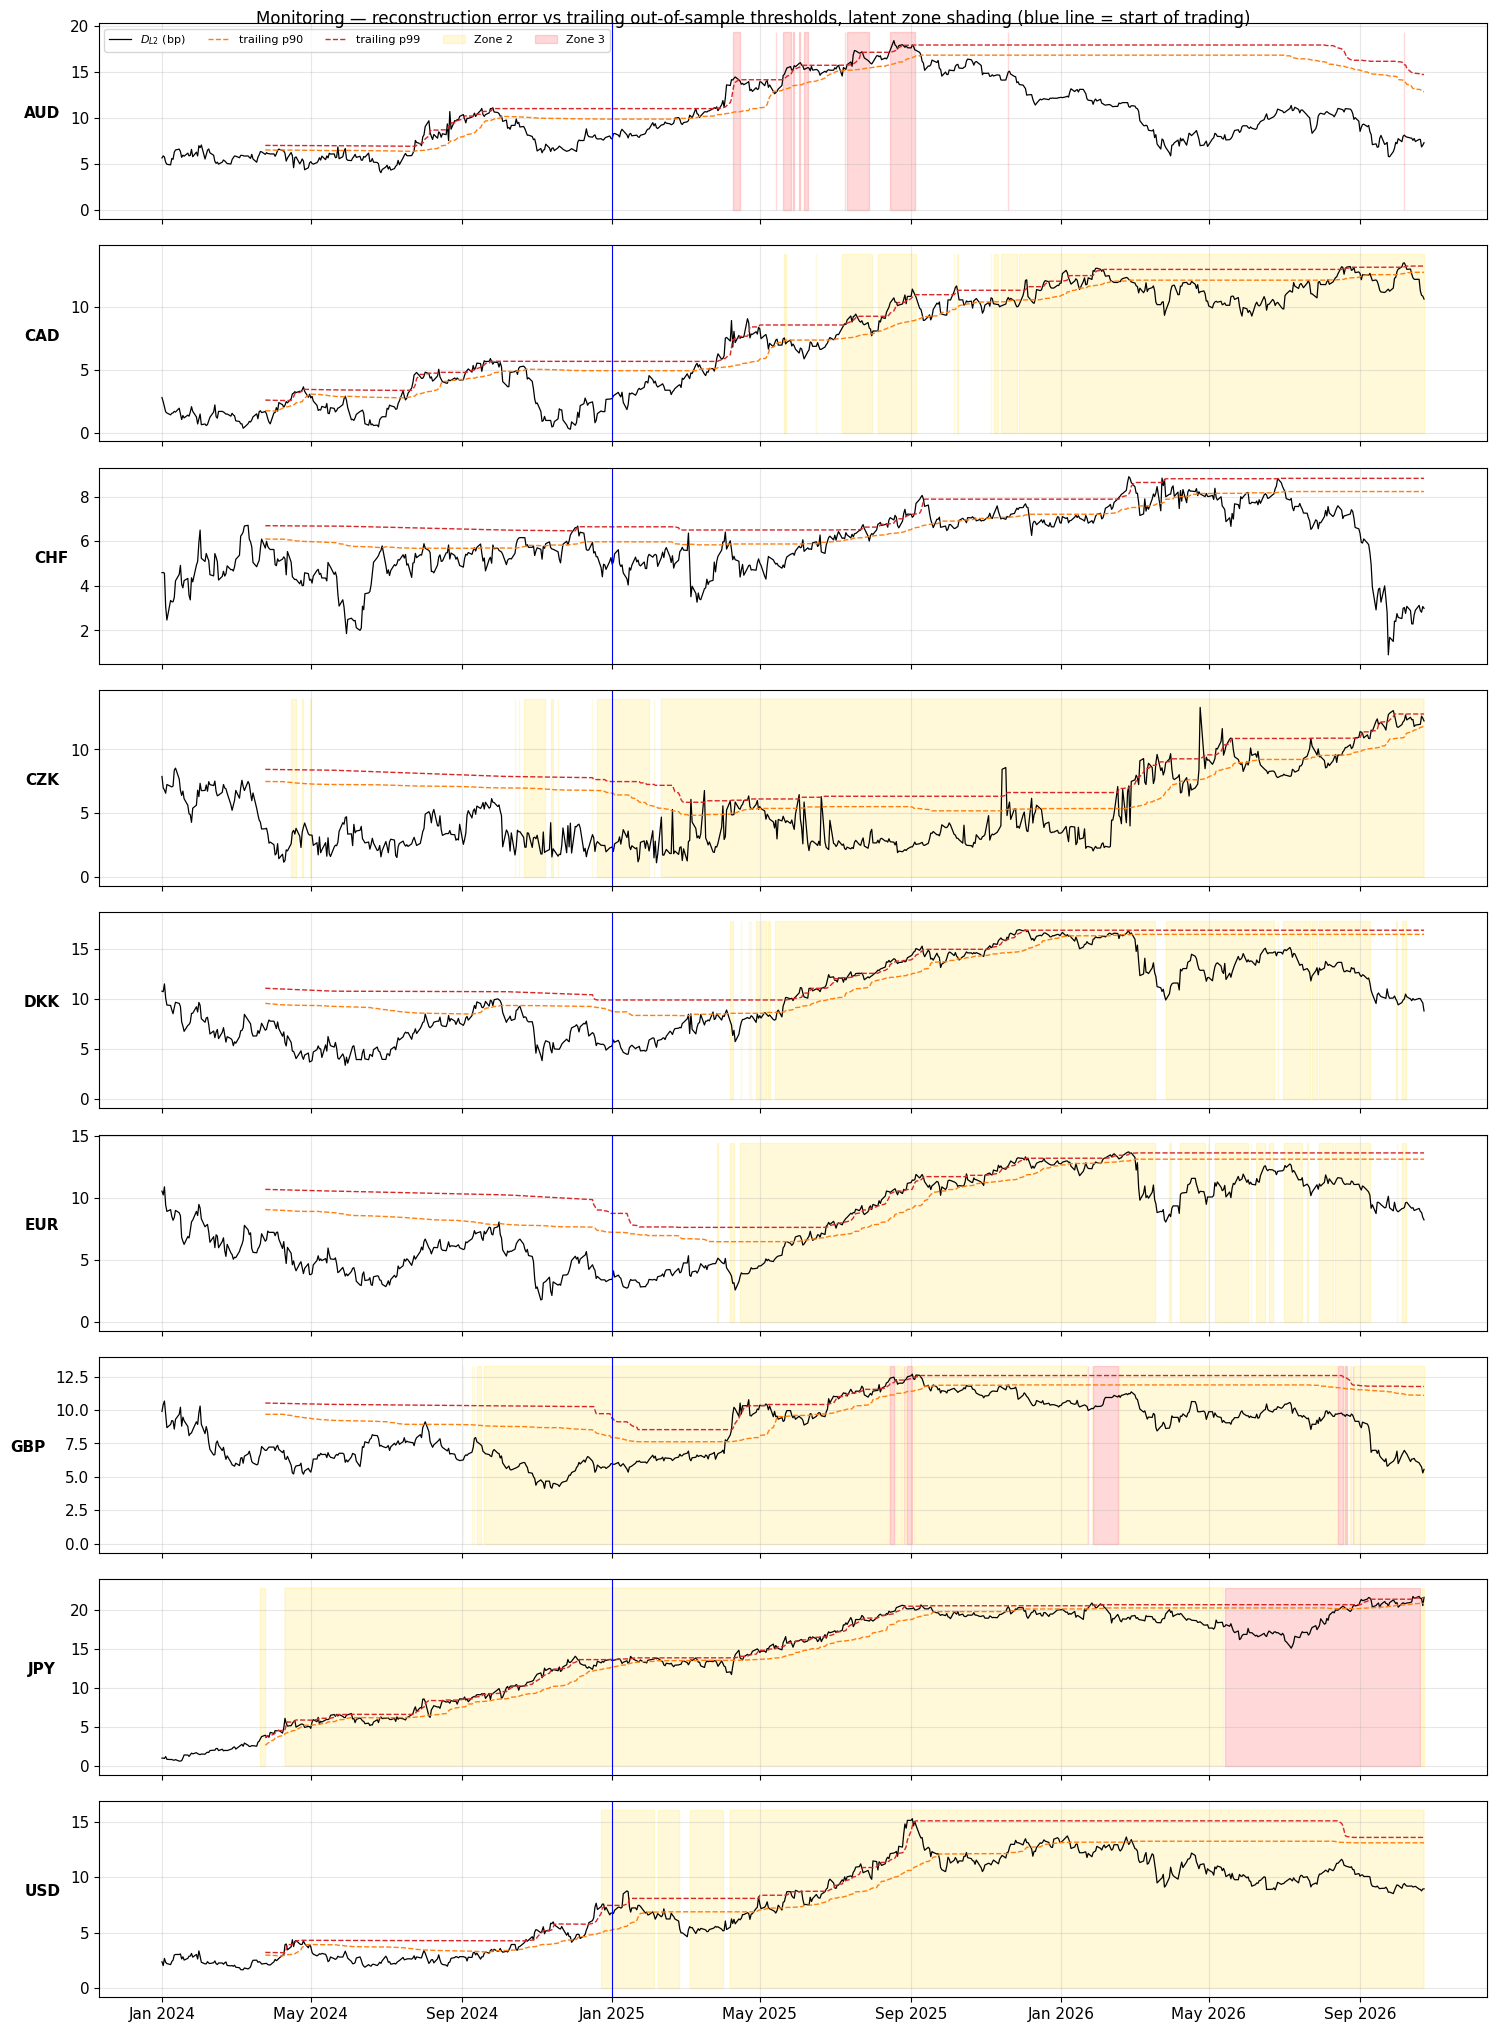

In [6]:
# Monitoring view: D_L2 with its trailing out-of-sample thresholds, and the latent zone underneath.
fig, axes = plt.subplots(N_CCY, 1, figsize=(15, 2.3 * N_CCY), sharex=True)
for ax, c in zip(axes, CURRENCIES):
    s = DL2[c][post_mask]
    hist = DL2[c].where(post_mask)
    p90 = hist.rolling(P["HIST_WINDOW"], min_periods=P["MIN_HIST"]).quantile(0.90).shift(1)[post_mask]
    p99 = hist.rolling(P["HIST_WINDOW"], min_periods=P["MIN_HIST"]).quantile(0.99).shift(1)[post_mask]
    ax.plot(s.index, s, lw=0.9, color="black", label="$D_{L2}$ (bp)")
    ax.plot(p90.index, p90, lw=1, ls="--", color="tab:orange", label="trailing p90")
    ax.plot(p99.index, p99, lw=1, ls="--", color="tab:red", label="trailing p99")
    for k, col in [(2, "gold"), (3, "red")]:
        zk = zone[c][post_mask] == k
        ax.fill_between(s.index, 0, s.max() * 1.05, where=zk.values, color=col, alpha=0.15, step="mid",
                        label=f"Zone {k}")
    ax.axvline(TRADE_START, color="blue", lw=0.8)
    ax.set_ylabel(c, rotation=0, labelpad=20, fontweight="bold")
axes[0].legend(ncol=5, fontsize=8, loc="upper left")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.suptitle("Monitoring — reconstruction error vs trailing out-of-sample thresholds, latent zone shading "
             "(blue line = start of trading)", fontsize=12)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig_nb5_monitoring.png", dpi=130, bbox_inches="tight"); plt.show()

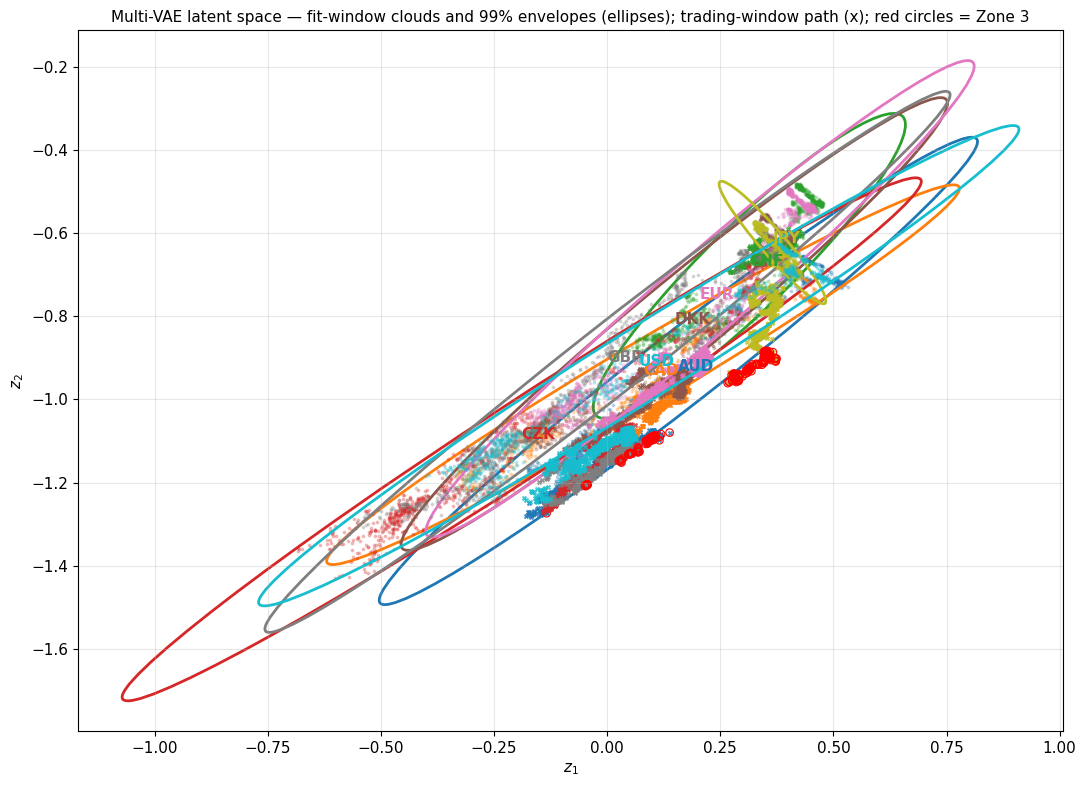

In [7]:
# Latent map: fit-window clouds with their envelopes, and the out-of-sample path coloured by zone.
from matplotlib.patches import Ellipse
fig, ax = plt.subplots(figsize=(11, 8))
colors = plt.cm.tab10(np.linspace(0, 1, N_CCY))
for col, c in zip(colors, CURRENCIES):
    Z = z_lat[c]
    ax.scatter(Z[fit_mask, 0], Z[fit_mask, 1], s=3, alpha=0.25, color=col)
    vals, vecs = np.linalg.eigh(env[c]["cov"])
    ang = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
    w, h = 2 * env[c]["radius"] * np.sqrt(vals[1]), 2 * env[c]["radius"] * np.sqrt(vals[0])
    ax.add_patch(Ellipse(env[c]["mean"], w, h, angle=ang, fill=False, lw=2, color=col))
    ax.annotate(c, env[c]["mean"], fontweight="bold", color=col, fontsize=11)
    oos = Z[trade_mask]
    zt = zone[c][trade_mask].values
    ax.scatter(oos[:, 0], oos[:, 1], s=8, marker="x", color=col, alpha=0.8)
    ax.scatter(oos[zt == 3, 0], oos[zt == 3, 1], s=30, facecolors="none", edgecolors="red", lw=0.8)
ax.set_xlabel("$z_1$"); ax.set_ylabel("$z_2$")
ax.set_title("Multi-VAE latent space — fit-window clouds and 99% envelopes (ellipses); trading-window path (x); "
             "red circles = Zone 3", fontsize=11)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig_nb5_latent_zones.png", dpi=130, bbox_inches="tight"); plt.show()

## 2 — Residual decomposition & trade construction

### 2.1 Where is the mispricing?
The per-tenor residual vector $r_t = S_t - S'_t$ tells us *which* tenors are off the manifold. A
positive $r_k$ means tenor $k$ trades **cheap** (yield too high) relative to the shape the model
considers plausible; negative means **rich**. Two diagnostics describe its shape:
- **per-tenor z-scores** (trailing out-of-sample), to see which points are unusual;
- **concentration** $= \max_k r_k^2 / \sum_k r_k^2$: close to 1 when one tenor carries the distortion
  (typical of a liquidity / supply effect), small when the whole shape is new (typical of a regime move).

### 2.2 From residuals to hedged packages
A package is a vector of DV01 risk weights $w$ on tenors; its value is $V_t = w^\top S_t$ (bp) and its
**dislocation** is $R_t = w^\top r_t$ (bp). We consider:

- **Butterflies** (8 structures: 2s3s5s, 2s5s10s, 3s5s10s, 5s10s15s, 5s10s30s, 10s15s20s, 10s20s30s,
  15s20s30s). Weights are **model-neutral**: the belly weight is 1 and the wings solve
  $J_{\text{legs}}^\top w = 0$, where $J = \partial S'/\partial z$ is the decoder Jacobian at the
  currency's typical latent point. The fly is then immune (to first order) to *both* latent factors —
  any move along the manifold — and only exposed to the off-manifold mispricing. If the solution is
  ill-conditioned (wing weights not negative or above 3 in size) we fall back to the standard 50/50
  DV01-neutral fly.
- **Steepeners / flatteners** (4 spreads: 2s5s, 2s10s, 5s30s, 10s30s), DV01-neutral $(-1, +1)$.
  They hedge parallel moves but stay exposed to the slope factor, so they need larger dislocations to
  be competitive (same z-score threshold, more P&L noise).

Weights are computed once per (currency, structure) at the currency's average fit-window latent point
and kept fixed, so each package has a clean, tradable history. Because the decoder is nonlinear, the
neutrality is only local: as the curve drifts away from that point the fly picks up some factor exposure
(one more reason to stop trading when the drift ratio of §1.2 is high). A model-neutral fly also needs
a well-conditioned leg Jacobian (smallest/largest singular value ≥ 0.05); otherwise we use 50/50.

In [8]:
FLIES = [(2, 3, 5), (2, 5, 10), (3, 5, 10), (5, 10, 15), (5, 10, 30), (10, 15, 20), (10, 20, 30), (15, 20, 30)]
SPREADS = [(2, 5), (2, 10), (5, 30), (10, 30)]
T_IDX = {t: i for i, t in enumerate(TENORS)}


def decoder_jacobian(ccy, z):
    y = one_hot(ccy, 1)[0]
    f = lambda zz: cvae.decode(zz.unsqueeze(0), y.unsqueeze(0))[0] * (S_MAX - S_MIN) * BP   # bp per unit z
    return torch.autograd.functional.jacobian(f, torch.tensor(z, dtype=torch.float32)).numpy()   # (7, 2)


def make_structures(model_neutral: bool):
    structs, rows = {}, []
    for c in CURRENCIES:
        J = decoder_jacobian(c, z_star[c][fit_mask].mean(0)) if model_neutral else None
        lst = []
        for legs in FLIES:
            ok = False
            if model_neutral:
                Js = J[[T_IDX[t] for t in legs]]
                sv = np.linalg.svd(Js, compute_uv=False)
                w = np.cross(Js[:, 0], Js[:, 1])                       # null vector of Js^T
                if sv[-1] / sv[0] >= P["JAC_COND_MIN"] and abs(w[1]) > 1e-12:
                    w = w / w[1]
                    ok = w[0] < 0 and w[2] < 0 and np.max(np.abs(w)) <= 3
            if not ok:
                w = np.array([-0.5, 1.0, -0.5])
            name = "fly " + "s".join(map(str, legs)) + "s"
            lst.append(dict(name=name, legs=list(legs), w=w, kind="fly", hedge="model-neutral" if ok else "50/50"))
            rows.append({"currency": c, "structure": name, "weights": np.round(w, 2), "hedge": lst[-1]["hedge"]})
        for legs in SPREADS:
            lst.append(dict(name=f"{legs[0]}s{legs[1]}s", legs=list(legs), w=np.array([-1.0, 1.0]), kind="spread",
                            hedge="DV01-neutral"))
        structs[c] = lst
    return structs, pd.DataFrame(rows)


structures, w_table = make_structures(model_neutral=True)
print(f"Butterfly weights (belly = 1): {(w_table['hedge'] == 'model-neutral').mean():.0%} of flies use the "
      "decoder-Jacobian (model-neutral) hedge, the rest the 50/50 fallback")
w_table.pivot(index="structure", columns="currency", values="weights")

Butterfly weights (belly = 1): 79% of flies use the decoder-Jacobian (model-neutral) hedge, the rest the 50/50 fallback


currency,AUD,CAD,CHF,CZK,DKK,EUR,GBP,JPY,USD
structure,,,,,,,,,
fly 10s15s20s,"[-0.5, 1.0, -0.5]","[-0.5, 1.0, -0.5]","[-0.3, 1.0, -0.7]","[-0.5, 1.0, -0.5]","[-0.35, 1.0, -0.67]","[-0.36, 1.0, -0.65]","[-0.5, 1.0, -0.5]","[-0.52, 1.0, -0.52]","[-0.5, 1.0, -0.5]"
fly 10s20s30s,"[-0.12, 1.0, -0.95]","[-0.5, 1.0, -0.5]","[-0.01, 1.0, -0.97]","[-0.5, 1.0, -0.5]","[-0.18, 1.0, -0.9]","[-0.16, 1.0, -0.9]","[-0.21, 1.0, -0.82]","[-0.34, 1.0, -0.74]","[-0.5, 1.0, -0.5]"
fly 15s20s30s,"[-0.5, 1.0, -0.5]","[-0.5, 1.0, -0.5]","[-0.5, 1.0, -0.5]","[-0.5, 1.0, -0.5]","[-0.38, 1.0, -0.67]","[-0.34, 1.0, -0.7]","[-0.5, 1.0, -0.5]","[-0.49, 1.0, -0.55]","[-0.5, 1.0, -0.5]"
fly 2s3s5s,"[-0.62, 1.0, -0.32]","[-0.55, 1.0, -0.42]","[-0.72, 1.0, -0.26]","[-0.59, 1.0, -0.33]","[-0.8, 1.0, -0.16]","[-0.81, 1.0, -0.15]","[-0.69, 1.0, -0.23]","[-0.5, 1.0, -0.5]","[-0.6, 1.0, -0.34]"
fly 2s5s10s,"[-0.38, 1.0, -0.51]","[-0.3, 1.0, -0.63]","[-0.54, 1.0, -0.44]","[-0.34, 1.0, -0.53]","[-0.57, 1.0, -0.36]","[-0.59, 1.0, -0.36]","[-0.44, 1.0, -0.44]","[-1.75, 1.0, -0.1]","[-0.35, 1.0, -0.54]"
fly 3s5s10s,"[-0.51, 1.0, -0.43]","[-0.44, 1.0, -0.51]","[-0.63, 1.0, -0.37]","[-0.48, 1.0, -0.45]","[-0.64, 1.0, -0.33]","[-0.65, 1.0, -0.32]","[-0.56, 1.0, -0.39]","[-0.95, 1.0, -0.23]","[-0.49, 1.0, -0.45]"
fly 5s10s15s,"[-0.22, 1.0, -0.78]","[-0.18, 1.0, -0.82]","[-0.29, 1.0, -0.72]","[-0.21, 1.0, -0.8]","[-0.29, 1.0, -0.72]","[-0.3, 1.0, -0.71]","[-0.24, 1.0, -0.76]","[-0.37, 1.0, -0.66]","[-0.21, 1.0, -0.79]"
fly 5s10s30s,"[-0.27, 1.0, -0.82]","[-0.16, 1.0, -1.02]","[-0.37, 1.0, -0.62]","[-0.22, 1.0, -0.83]","[-0.43, 1.0, -0.65]","[-0.45, 1.0, -0.62]","[-0.34, 1.0, -0.67]","[-0.68, 1.0, -0.47]","[-0.24, 1.0, -0.81]"


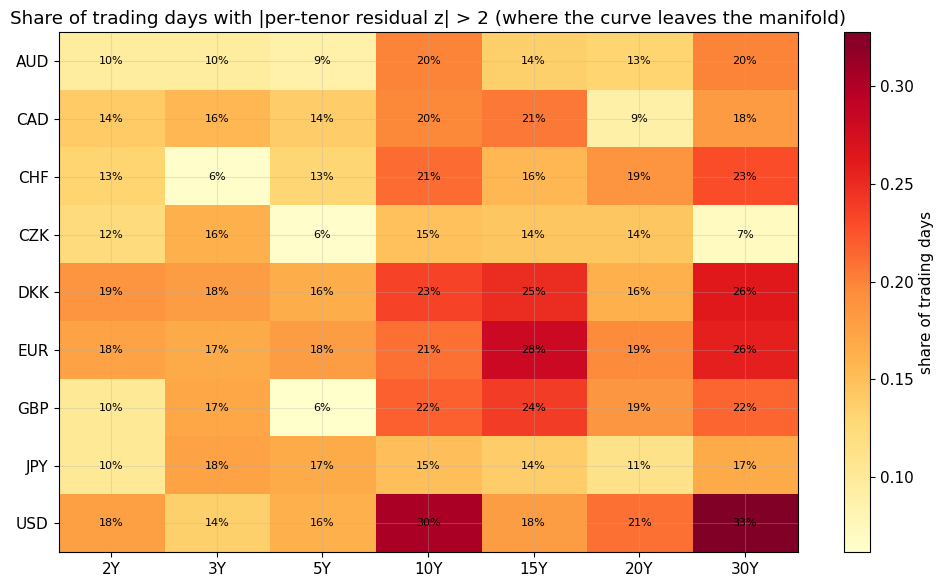

In [9]:
def build_packages(resid_by_ccy, structs):
    """Package value V, dislocation R, z-score of R, and daily-change volatility, per (ccy, structure)."""
    pk = {}
    for c in CURRENCIES:
        for s in structs[c]:
            Sbp = curves[c][s["legs"]] * BP
            V = Sbp @ s["w"]
            R = resid_by_ccy[c][s["legs"]] @ s["w"]
            pk[(c, s["name"])] = dict(spec=s, V=V, R=R, Z=trailing_post_stat(R, "z"),
                                      vol=V.diff().rolling(P["VOL_WINDOW"], min_periods=20).std())
    return pk


def make_context(name, resid_by_ccy, structs, dl2, dl2_pct, zones):
    """Everything the engine needs for one fair-value model."""
    return dict(name=name, structures=structs, pk=build_packages(resid_by_ccy, structs), dl2_pct=dl2_pct,
                conc=pd.DataFrame({c: (resid_by_ccy[c] ** 2).max(axis=1) / (resid_by_ccy[c] ** 2).sum(axis=1)
                                   for c in CURRENCIES}),
                breadth=(dl2_pct >= P["DL2_FLAG_PCT"]).sum(axis=1),
                drift=pd.DataFrame({c: drift_ratio(dl2[c]) for c in CURRENCIES}), zone=zones)


ctx_aemm = make_context("AEMM", resid, structures, DL2, DL2_pct, zone)
packages = ctx_aemm["pk"]

# Per-tenor residual z-scores in the trading window: which tenors are usually off the manifold?
tenor_z = {c: pd.DataFrame({t: trailing_post_stat(resid[c][t], "z") for t in TENORS}) for c in CURRENCIES}
heat = pd.DataFrame({c: (tenor_z[c][trade_mask].abs() > 2).mean() for c in CURRENCIES}).T
fig, ax = plt.subplots(figsize=(10, 0.5 * N_CCY + 1.5))
im = ax.imshow(heat.values, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(TENORS))); ax.set_xticklabels([f"{t}Y" for t in TENORS])
ax.set_yticks(range(N_CCY)); ax.set_yticklabels(heat.index)
for i in range(N_CCY):
    for j in range(len(TENORS)):
        ax.text(j, i, f"{heat.values[i, j]:.0%}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax, label="share of trading days")
ax.set_title("Share of trading days with |per-tenor residual z| > 2 (where the curve leaves the manifold)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig_nb5_residual_heatmap.png", dpi=130, bbox_inches="tight"); plt.show()

## 3 — Mean-reversion & execution logic

**Entry** (evaluated at each close $t$, filled at the next close $t+1$):
1. the curve is flagged: $D_{L2}$ percentile $\ge 90$ (§1.2);
2. the regime classification (§4) is not *regime shift*; position size is 100% for a *liquidity
   dislocation* and 50% when *uncertain*;
3. at least one package has $|Z| \ge 2$, a dislocation $|R|$ of at least 1 bp **and** twice its
   round-trip transaction cost, and $Z$ and $R$ of the same
   sign (the package is unusually far from its fair value, not merely less biased than usual); we take
   the package with the largest $|Z|$;
4. direction: **fade the dislocation**, i.e. position $= -\operatorname{sign}(R)$ — if the package is
   above its fair value we sell it, betting that "economic gravity" pulls the curve back toward the
   manifold;
5. size: $\text{TARGET\_VOL} / \sigma(\Delta V)$, so every trade carries about 1 bp of daily P&L
   volatility; one open trade per currency at a time.

**Exit** (first condition that triggers): take profit when $|Z| \le 0.5$; time stop after 20 business
days of holding;
plus the risk stops of §4. **Costs**: 0.25 bp per leg per unit DV01 on entry and on exit
(≈ half the bid/offer of liquid OIS); a fly therefore costs about $\sum_k |w_k| \times 0.25$ bp each way.

## 4 — Risk controls & stop-losses

The central risk of fading model residuals is that the model, not the market, is wrong: the curve has
moved to a shape the VAE has never seen, and the "dislocation" will not revert. We classify every
currency-day:

| Class | Rule | Action |
|---|---|---|
| **Regime shift** | Zone 3, **or** $D_{L2}$ ≥ p99 for 5 consecutive days, **or** drift ratio > 2 (§1.2), **or** Zone ≥ 2 with a broad residual while ≥ half of the currencies are flagged | no entries; exit open trades in that currency; 20-day cooldown. With a one-day execution delay an entry signalled the day before still fills; it is then closed by a regime stop the next day. |
| **Liquidity dislocation** | Zone 1 **and** residual concentrated (concentration ≥ 0.4) | trade at full size |
| **Uncertain** | everything else | trade at half size |

Per-trade stops:
- **Signal stop** — the dislocation keeps widening: $|Z| \ge 4$ in the direction of entry.
- **P&L stop** — the mark-to-market loss exceeds the dislocation we bet on ($1\times|R_{entry}|$ bp × size).
- **Time stop** — 20 business days of holding.

Portfolio stop: if the book loses more than 15 bp-risk units from its high-water mark, flatten
everything and pause new entries for 10 days; the high-water mark is then re-armed at the current level.

A regime classification is also a **model-governance event**: the curve has left the shapes the model
was validated on, and the model should be retrained before it is trusted again for that currency.

In [10]:
def classify(ctx, c, ti, run_extreme):
    zn, cc = ctx["zone"][c].iat[ti], ctx["conc"][c].iat[ti]
    dr = ctx["drift"][c].iat[ti]
    if zn == 3 or run_extreme >= P["EXTREME_RUN"] or (np.isfinite(dr) and dr > P["DRIFT_MAX"]):
        return "REGIME"
    if zn >= 2 and cc < P["CONC_LOCAL"] and ctx["breadth"].iat[ti] >= P["BREADTH_FRAC"] * N_CCY:
        return "REGIME"
    if zn == 1 and cc >= P["CONC_LOCAL"]:
        return "LIQUIDITY"
    return "UNCERTAIN"


def entry_candidate(ctx, c, ti, tc_leg=P["TC_LEG_BP"]):
    """Most dislocated eligible package for currency c at close ti, or None (the §3 entry rules)."""
    best = None
    for s in ctx["structures"][c]:
        p = ctx["pk"][(c, s["name"])]
        z, R, vol = p["Z"].iat[ti], p["R"].iat[ti], p["vol"].iat[ti]
        min_edge = max(P["MIN_EDGE_BP"], P["EDGE_COST_MULT"] * 2 * np.abs(s["w"]).sum() * tc_leg)
        if np.isfinite(z) and np.isfinite(vol) and vol > 0 and abs(z) >= P["Z_ENTRY"] \
                and np.sign(z) == np.sign(R) and abs(R) >= min_edge and (best is None or abs(z) > abs(best[1])):
            best = (s, z, R, vol)
    return best


def backtest(ctx, controls=True, exec_delay=P["EXEC_DELAY"], tc_leg=P["TC_LEG_BP"]):
    """Event-driven daily backtest over the trading window. Returns daily P&L per currency, trade log, classes."""
    pk, dl2_pct = ctx["pk"], ctx["dl2_pct"]
    tidx = np.where(trade_mask)[0]
    last_ti = tidx[-1]
    pnl = pd.DataFrame(0.0, index=dates[tidx], columns=CURRENCIES)
    open_tr = {c: None for c in CURRENCIES}
    pending = []                               # (exec_ti, action, ccy, payload)
    cooldown_until = {c: -1 for c in CURRENCIES}
    run_extreme = {c: 0 for c in CURRENCIES}
    port_cum, port_hwm, pause_until = 0.0, 0.0, -1
    log, classes = [], []

    def fill(ti, action, c, pay):
        if action == "enter" and open_tr[c] is None:
            if ti == last_ti:                  # no new position on the last day of the sample
                return
            s = pay["spec"]; V = pk[(c, s["name"])]["V"]
            cost = pay["size"] * np.abs(s["w"]).sum() * tc_leg
            pnl.at[dates[ti], c] -= cost
            open_tr[c] = dict(**pay, ccy=c, fill_ti=ti, V_prev=V.iat[ti], mtm=-cost, cost=cost)
        elif action == "exit" and open_tr[c] is not None:
            tr = open_tr[c]; cost = tr["size"] * np.abs(tr["spec"]["w"]).sum() * tc_leg
            pnl.at[dates[ti], c] -= cost
            tr.update(exit_ti=ti, reason=pay["reason"], mtm=tr["mtm"] - cost, cost=tr["cost"] + cost)
            log.append(tr); open_tr[c] = None

    def process_due(ti):
        for o in [o for o in pending if o[0] == ti]:
            pending.remove(o); fill(*o)

    def cancel_entries(ccys):
        for o in [o for o in pending if o[1] == "enter" and o[2] in ccys]:
            pending.remove(o)

    for ti in tidx:
        d = dates[ti]
        # 1) mark-to-market positions filled at a previous close
        for c, tr in open_tr.items():
            if tr is not None:
                V = pk[(c, tr["spec"]["name"])]["V"].iat[ti]
                ch = tr["size"] * tr["sign"] * (V - tr["V_prev"])
                pnl.at[d, c] += ch; tr["mtm"] += ch; tr["V_prev"] = V
        # 2) orders due at today's close
        process_due(ti)
        # 3) signals at today's close -> orders for close ti + exec_delay
        for c in CURRENCIES:
            pct = dl2_pct[c].iat[ti]
            run_extreme[c] = run_extreme[c] + 1 if pct >= P["DL2_EXTREME_PCT"] else 0
            cls = classify(ctx, c, ti, run_extreme[c]); classes.append((d, c, cls))
            busy = any(o[2] == c for o in pending)
            tr = open_tr[c]
            if tr is not None and not busy:
                z = pk[(c, tr["spec"]["name"])]["Z"].iat[ti]
                reason = None
                if abs(z) <= P["Z_EXIT"]:
                    reason = "take profit"
                elif ti - tr["fill_ti"] >= P["MAX_HOLD"] - exec_delay:
                    reason = "time stop"
                elif controls and np.sign(z) == np.sign(tr["z_entry"]) and abs(z) >= P["Z_STOP"]:
                    reason = "signal stop"
                elif controls and tr["mtm"] <= -P["STOP_MULT"] * abs(tr["R_entry"]) * tr["size"]:
                    reason = "P&L stop"
                elif controls and cls == "REGIME":
                    reason = "regime stop"
                if reason:
                    pending.append((ti + exec_delay, "exit", c, {"reason": reason}))
            if controls and cls == "REGIME":
                cooldown_until[c] = ti + P["COOLDOWN"]
                cancel_entries([c])
            if tr is None and not busy and ti >= cooldown_until[c] and ti > pause_until \
                    and pct >= P["DL2_FLAG_PCT"] and ti < last_ti:
                mult = {"LIQUIDITY": 1.0, "UNCERTAIN": 0.5, "REGIME": 0.0}[cls] if controls else 1.0
                best = entry_candidate(ctx, c, ti) if mult > 0 else None    # selection at the base cost
                if best:
                    s, z, R, vol = best
                    pending.append((ti + exec_delay, "enter", c, dict(
                        spec=s, sign=-np.sign(R), size=mult * P["TARGET_VOL_BP"] / vol, z_entry=z, R_entry=R,
                        signal_date=d, cls=cls, zone=int(ctx["zone"][c].iat[ti]))))
        # 4) portfolio stop on the day's P&L. With same-close execution it is checked before today's
        #    fills, so a stop cancels same-day entries instead of opening and closing them at once.
        def portfolio_stop():
            nonlocal pause_until, port_hwm
            if controls and ti > pause_until and port_hwm - (port_cum + pnl.loc[d].sum()) > P["PORT_DD_STOP"]:
                for c in CURRENCIES:
                    if open_tr[c] is not None and not any(o[2] == c and o[1] == "exit" for o in pending):
                        pending.append((ti + exec_delay, "exit", c, {"reason": "portfolio stop"}))
                cancel_entries(CURRENCIES)
                pause_until = ti + P["PORT_PAUSE"]
                return True
            return False
        stopped = portfolio_stop()
        if exec_delay == 0:
            process_due(ti)
        if stopped:
            port_hwm = port_cum + pnl.loc[d].sum()              # re-arm at the current level
        port_cum += pnl.loc[d].sum()
        port_hwm = max(port_hwm, port_cum)
    for c in CURRENCIES:                                        # close anything still open at the end
        if open_tr[c] is not None:
            fill(last_ti, "exit", c, {"reason": "end of sample"})
    trades = pd.DataFrame([{
        "currency": t["ccy"], "structure": t["spec"]["name"], "kind": t["spec"]["kind"],
        "signal_date": t["signal_date"], "entry": dates[t["fill_ti"]], "exit": dates[t["exit_ti"]],
        "days": t["exit_ti"] - t["fill_ti"], "class": t["cls"], "zone": t["zone"], "z_entry": t["z_entry"],
        "R_entry_bp": t["R_entry"], "size": t["size"], "pnl": t["mtm"], "cost": t["cost"], "exit_reason": t["reason"]}
        for t in log])
    return pnl, trades, pd.DataFrame(classes, columns=["date", "currency", "class"])


def perf(daily: pd.Series) -> dict:
    daily = daily.fillna(0.0)
    cum = daily.cumsum()
    sd = daily.std()
    return {"Sharpe": daily.mean() / sd * np.sqrt(252) if sd > 0 else 0.0, "Sharpe SE": np.sqrt(252 / len(daily)),
            "Total (bp-risk)": cum.iloc[-1], "Max DD": (cum - cum.cummax()).min()}


def summarize(label, pnl, trades):
    port = pnl.sum(axis=1)
    out = {"variant": label, **perf(port), "trades": len(trades)}
    if len(trades):
        out.update({"trade hit rate": (trades["pnl"] > 0).mean(), "avg days held": trades["days"].mean(),
                    "costs (bp-risk)": trades["cost"].sum()})
    return out

### Classification of every currency-day in the trading window

In [11]:
pnl_main, trades_main, classes_main = backtest(ctx_aemm, controls=True)
cls_share = (classes_main.groupby(["currency", "class"]).size().unstack(fill_value=0)
             .pipe(lambda t: t.div(t.sum(axis=1), axis=0)))
print("Share of trading-window days by regime class:")
(cls_share * 100).round(0).astype(int).astype(str) + "%"

Share of trading-window days by regime class:


class,LIQUIDITY,REGIME,UNCERTAIN
currency,,,
AUD,63%,32%,5%
CAD,5%,87%,8%
CHF,8%,1%,91%
CZK,1%,47%,53%
DKK,17%,43%,40%
EUR,17%,49%,34%
GBP,0%,7%,93%
JPY,0%,85%,15%
USD,1%,89%,10%


## 5 — Backtest, benchmarks & assessment

Variants (all on the same 2025–2026 trading window and parameters):
- **AEMM RV (full)** — the strategy above.
- **No risk controls** — same signals, only take-profit and time stop (no regime / signal / P&L /
  portfolio stops, no size reduction).
- **NS fair value (classical engine)** — the fair value $S'$ is a per-date Nelson-Siegel fit (λ chosen
  by pooled cross-validation on the fit window only), flies are 50/50 DV01-neutral, and there are no
  latent zones (every day counts as Zone 1). Thresholds, drift ratio and concentration are computed
  from the NS residuals. This compares two complete systems (classical vs. AEMM: fair value **and**
  latent zones **and** the drift gate), not the fair values alone.
- **Same-close execution** — fill at the signal close (the NB4 convention).
- **Cost sensitivity** — 0 and 0.5 bp per leg (trade selection kept at the base 0.25 bp, so only the
  charged costs change).

In [12]:
# NS benchmark fair value: lambda by pooled CV on the fit window only (same grid as NB2)
tau = np.array(TENORS, dtype=float)


def ns_basis(lam):
    lt = lam * tau; f1 = (1 - np.exp(-lt)) / lt
    return np.column_stack([np.ones_like(tau), f1, f1 - np.exp(-lt)])


fit_rates = np.vstack([curves[c].loc[fit_mask].values for c in CURRENCIES])
cv = {lam: np.sqrt(((fit_rates - (ns_basis(lam) @ np.linalg.lstsq(ns_basis(lam), fit_rates.T, rcond=None)[0]).T) ** 2)
                   .mean(1)).mean() for lam in np.linspace(0.05, 2.0, 40)}
LAM_FIT = min(cv, key=cv.get)
resid_ns, DL2_ns = {}, {}
for c in CURRENCIES:
    B = ns_basis(LAM_FIT)
    fitted = (B @ np.linalg.lstsq(B, curves[c].values.T, rcond=None)[0]).T
    resid_ns[c] = (curves[c] - fitted) * BP
    DL2_ns[c] = np.sqrt((resid_ns[c] ** 2).mean(axis=1))
DL2_ns_pct = pd.DataFrame({c: trailing_post_stat(DL2_ns[c], "pct") for c in CURRENCIES})
structures_ns, _ = make_structures(model_neutral=False)
ctx_ns = make_context("NS", resid_ns, structures_ns, DL2_ns, DL2_ns_pct,
                      pd.DataFrame(1, index=dates, columns=CURRENCIES))
print(f"NS lambda (fit-window CV) = {LAM_FIT:.3f}")

variants = {
    "AEMM RV (full)": (pnl_main, trades_main),
    "AEMM RV, no risk controls": backtest(ctx_aemm, controls=False)[:2],
    "NS fair value (classical engine)": backtest(ctx_ns, controls=True)[:2],
    "AEMM RV, same-close execution": backtest(ctx_aemm, controls=True, exec_delay=0)[:2],
    "AEMM RV, cost 0 bp/leg": backtest(ctx_aemm, controls=True, tc_leg=0.0)[:2],
    "AEMM RV, cost 0.5 bp/leg": backtest(ctx_aemm, controls=True, tc_leg=0.5)[:2],
}
results = pd.DataFrame([summarize(k, *v) for k, v in variants.items()]).set_index("variant")
results.round(2)

NS lambda (fit-window CV) = 0.450


,Sharpe,Sharpe SE,Total (bp-risk),Max DD,trades,trade hit rate,avg days held,costs (bp-risk)
variant,,,,,,,,
AEMM RV (full),-1.70,0.73,-31.59,-32.50,34,0.09,9.71,25.30
"AEMM RV, no risk controls",-2.72,0.73,-206.10,-206.96,95,0.15,17.48,188.60
NS fair value (classical engine),-1.06,0.73,-30.63,-30.84,50,0.36,7.80,52.50
"AEMM RV, same-close execution",-1.02,0.73,-21.92,-26.96,33,0.30,10.73,24.50
"AEMM RV, cost 0 bp/leg",-0.56,0.73,-10.96,-16.08,36,0.50,9.92,0.00
"AEMM RV, cost 0.5 bp/leg",-2.43,0.73,-62.68,-62.68,34,0.03,8.74,46.67


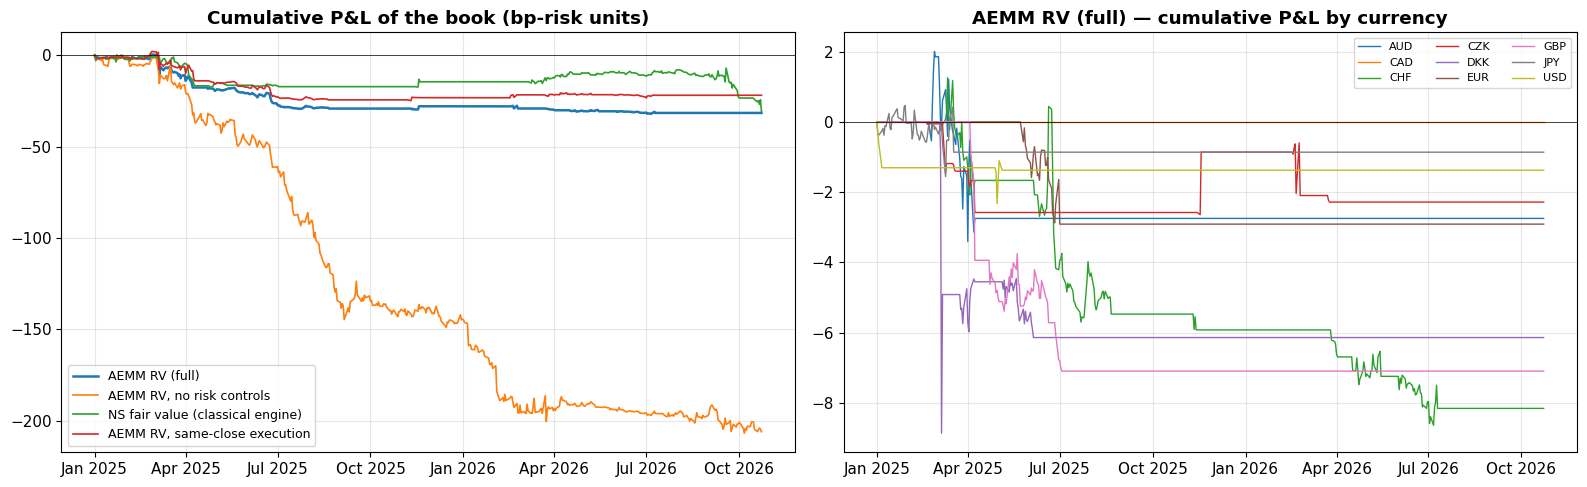

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for k in ["AEMM RV (full)", "AEMM RV, no risk controls", "NS fair value (classical engine)", "AEMM RV, same-close execution"]:
    axes[0].plot(variants[k][0].sum(axis=1).cumsum(), lw=1.8 if "full" in k else 1.2, label=k)
axes[0].axhline(0, color="black", lw=0.5)
axes[0].set_title("Cumulative P&L of the book (bp-risk units)", fontweight="bold")
axes[0].legend(fontsize=9); axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
pc = pnl_main.cumsum()
for c in CURRENCIES:
    axes[1].plot(pc[c], lw=1, label=c)
axes[1].axhline(0, color="black", lw=0.5)
axes[1].set_title("AEMM RV (full) — cumulative P&L by currency", fontweight="bold")
axes[1].legend(ncol=3, fontsize=8); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.tight_layout(); plt.savefig(FIG_DIR / "fig_nb5_pnl.png", dpi=130, bbox_inches="tight"); plt.show()

In [14]:
t = trades_main
if len(t):
    print("Exit reasons:"); print(t["exit_reason"].value_counts().to_string()); print()
    print("P&L by structure type and regime class at entry (bp-risk units):")
    print(t.groupby(["kind", "class"])["pnl"].agg(["count", "sum", "mean"]).round(2).to_string()); print()
    print("Per-trade statistics by structure (top 10 by count):")
    print(t.groupby("structure").agg(trades=("pnl", "size"), hit_rate=("pnl", lambda x: (x > 0).mean()),
                                     total_pnl=("pnl", "sum"), avg_days=("days", "mean"))
            .sort_values("trades", ascending=False).head(10).round(2).to_string())
else:
    print("No trades were taken.")

Exit reasons:
exit_reason
time stop         12
regime stop        9
take profit        5
portfolio stop     5
signal stop        2
P&L stop           1

P&L by structure type and regime class at entry (bp-risk units):
                  count    sum  mean
kind   class                        
fly    LIQUIDITY      4  -7.30 -1.83
       UNCERTAIN     25 -18.75 -0.75
spread LIQUIDITY      1  -2.73 -2.73
       UNCERTAIN      4  -2.81 -0.70

Per-trade statistics by structure (top 10 by count):
               trades  hit_rate  total_pnl  avg_days
structure                                           
fly 15s20s30s       6      0.17      -7.90      9.17
fly 10s20s30s       5      0.20      -4.45     14.60
fly 5s10s15s        5      0.00      -7.61     11.60
fly 10s15s20s       4      0.00      -2.03      8.25
fly 3s5s10s         4      0.00      -2.77     12.00
10s30s              3      0.00      -3.17     14.67
fly 5s10s30s        3      0.33      -0.07      2.00
5s30s               2      0.

### Monitoring snapshot — what the desk would see on the last date

In [15]:
ti = len(dates) - 1
snap = []
for c in CURRENCIES:
    run = int((DL2_pct[c].iloc[:ti + 1][::-1] >= P["DL2_EXTREME_PCT"]).astype(int).cummin().sum())
    cls = classify(ctx_aemm, c, ti, run)
    top = max(structures[c], key=lambda s: abs(np.nan_to_num(packages[(c, s["name"])]["Z"].iat[ti])))
    p = packages[(c, top["name"])]
    worst_tenor = resid[c].iloc[ti].abs().idxmax()
    cand = entry_candidate(ctx_aemm, c, ti)
    signal = "—"
    if cand and DL2_pct[c].iat[ti] >= P["DL2_FLAG_PCT"] and cls != "REGIME":
        signal = ("SELL " if cand[2] > 0 else "BUY ") + cand[0]["name"] + (" (half size)" if cls == "UNCERTAIN" else "")
    snap.append({"currency": c, "D_L2 (bp)": DL2[c].iat[ti], "D_L2 pct": DL2_pct[c].iat[ti],
                 "drift ratio": drift[c].iat[ti], "zone": zone[c].iat[ti], "class": cls,
                 "most off-manifold tenor": f"{worst_tenor}Y ({resid[c].iloc[ti][worst_tenor]:+.1f} bp)",
                 "most dislocated package": top["name"], "package z": p["Z"].iat[ti], "dislocation (bp)": p["R"].iat[ti],
                 "trade signal": signal})
print(f"As of {dates[ti].date()}:")
pd.DataFrame(snap).set_index("currency").round(2)

As of 2026-10-23:


,D_L2 (bp),D_L2 pct,drift ratio,zone,class,most off-manifold tenor,most dislocated package,package z,dislocation (bp),trade signal
currency,,,,,,,,,,
AUD,7.34,11.6,1.09,1,LIQUIDITY,30Y (+12.5 bp),fly 15s20s30s,2.05,-3.45,—
CAD,10.59,26.4,4.94,2,REGIME,30Y (+22.2 bp),5s30s,-2.52,21.70,—
CHF,2.99,7.6,0.54,1,UNCERTAIN,30Y (+4.8 bp),fly 10s15s20s,2.63,-2.06,—
CZK,12.24,94.0,3.11,2,REGIME,3Y (+16.2 bp),fly 2s3s5s,1.79,22.08,—
DKK,8.80,0.0,1.48,1,UNCERTAIN,5Y (+11.9 bp),fly 10s15s20s,2.83,-4.43,—
EUR,8.22,0.4,1.65,1,UNCERTAIN,5Y (+11.4 bp),fly 5s10s30s,2.82,-16.08,—
GBP,5.56,0.4,0.93,2,UNCERTAIN,3Y (+8.7 bp),fly 5s10s15s,3.41,-7.37,—
JPY,21.60,99.2,3.07,2,REGIME,30Y (+35.4 bp),2s5s,-2.77,-39.13,—
USD,8.95,5.6,2.77,2,REGIME,30Y (+13.7 bp),fly 5s10s30s,1.68,-22.87,—


In [16]:
res_main = results.loc["AEMM RV (full)"]
ns_row = results.loc["NS fair value (classical engine)"]
nc_row = results.loc["AEMM RV, no risk controls"]
sc_row = results.loc["AEMM RV, same-close execution"]
reg_share = (classes_main["class"] == "REGIME").mean()
print("ASSESSMENT (computed from the results above)")
print(f"- Out-of-sample Sharpe of the full strategy: {res_main['Sharpe']:.2f} (standard error ≈ {res_main['Sharpe SE']:.2f}), "
      f"{int(res_main['trades'])} trades, total {res_main['Total (bp-risk)']:.1f} bp-risk units.")
sig = abs(res_main["Sharpe"]) > 2 * res_main["Sharpe SE"]
print("- " + (f"Significantly {'positive' if res_main['Sharpe'] > 0 else 'negative'} at ~2 standard errors."
              if sig else "Not statistically distinguishable from zero at ~2 standard errors."))
print(f"- Versus the classical NS engine: {res_main['Sharpe'] - ns_row['Sharpe']:+.2f} Sharpe; "
      f"versus no risk controls: {res_main['Sharpe'] - nc_row['Sharpe']:+.2f}; "
      f"same-close execution: {sc_row['Sharpe'] - res_main['Sharpe']:+.2f}.")
print(f"- Currency-days classified as regime shift in the trading window: {reg_share:.0%} "
      f"(model trained on data up to {FIT_END.date()}).")
print("- Caveats: the standard error assumes independent daily P&L and ignores that several variants were tried.")

ASSESSMENT (computed from the results above)
- Out-of-sample Sharpe of the full strategy: -1.70 (standard error ≈ 0.73), 34 trades, total -31.6 bp-risk units.
- Significantly negative at ~2 standard errors.
- Versus the classical NS engine: -0.64 Sharpe; versus no risk controls: +1.02; same-close execution: +0.67.
- Currency-days classified as regime shift in the trading window: 49% (model trained on data up to 2023-12-31).
- Caveats: the standard error assumes independent daily P&L and ignores that several variants were tried.


### How to read these results
- The **framework** — monitoring, decomposition into hedged packages, execution rules and the
  liquidity-vs-regime classification — is the deliverable; the backtest is its out-of-sample test with
  one model trained on 2020–2023 and never retrained.
- The **regime-class shares** and the **drift ratio** show how quickly a fixed model leaves the shapes
  it was validated on. In production a regime classification would trigger **retraining** (e.g.
  quarterly, walk-forward; `scripts/audit/exp5_walkforward.py` is a template).
- The **NS (classical engine)** row compares the AEMM system with a complete classical one (fair value,
  zones and drift gate all differ); the **no risk controls** row shows what the controls change; the **same-close** row shows how sensitive the result
  is to trading at the very price that generated the signal.